# Cirrus cloud analysis: fixed cirrus vs wrong cirrus

Compare the two ICON R2B4 experiments using **all cloud tracks**, with one section per plot: time-averaged cloud area, cloud lifetime, time-averaged cloud-top temperature, and cloud counts. No event tables are loaded.

The visual style follows `model_vs_satellite_plots_resolution.ipynb`: Lipari categorical colors, transparent backgrounds, 10.5 × 5.6 inch figures, circle markers, and open top/right spines. Unlike its lifetime/area cells, these distributions use the full cloud population rather than an event-selected subset.

Run the notebook from top to bottom. Dependencies: pandas, numpy, pyarrow, matplotlib, cmcrameri, and IPython.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cmcrameri.cm
from IPython.display import display

%matplotlib inline

RESULT_DIRS = {
    "fcirrus": Path("/wolke_scratch/dnikolo/ICON_Data/cirrus/R2B4/fcirrus/postprocessing_output"),
    "wcirrus": Path("/wolke_scratch/dnikolo/ICON_Data/cirrus/R2B4/wcirrus/postprocessing_output"),
}
YEAR = 2007
# None selects the overlapping full calendar days available in both runs.
# Overrides select tracks by their start time: START_TIME <= start < END_TIME.
START_TIME = None  # e.g. "2007-04-01"
END_TIME = None    # e.g. "2007-05-15" (exclusive)
EXCLUDE_LARGE_PIXEL_CLOUDS = True
MIN_ABS_LATITUDE = 30
TEMPERATURE_OFFSET_K = 273  # Match the cirrus preprocessing convention.
SAVE_FIGURES = True
FIGURE_DIR = Path("/wolke_scratch/dnikolo/MSGI/figures/cirrus")

LABELS = {"fcirrus": "ICON R2B4 fixed cirrus", "wcirrus": "ICON R2B4 wrong cirrus"}
COLORS = {"fcirrus": cmcrameri.cm.lipariS(3), "wcirrus": cmcrameri.cm.lipariS(2)}

## Load cloud results and select the comparison period

Read only scalar columns from `Final_results/2007_all.parquet`. Apply the reference loader's filters (exclude `is_large_pix_cloud`; require |average latitude| > 30°), without requiring optical-property validity or any event classification.

The source files have different start dates. The default comparison uses their overlapping calendar days; both hemispheres and all six tracked cirrus temperature bins are pooled. A track is one row in a temperature-bin/hemisphere tracking population, not a deduplicated physical cloud across bins. The summary reports source coverage and rows retained. Inferred coverage uses track start dates, not an independent processing-completeness record.

In [2]:
columns = [
    "track_start_time", "track_length", "avg_size[km]", "avg_ctt",
    "is_large_pix_cloud", "avg_lat", "min_temp", "max_temp", "pole",
]
raw_clouds = {}
for run, directory in RESULT_DIRS.items():
    source = directory / "Final_results" / f"{YEAR}_all.parquet"
    if not source.is_file():
        raise FileNotFoundError(source)
    df = pd.read_parquet(source, columns=columns)
    df["track_start_time"] = pd.to_datetime(df["track_start_time"])
    if df["track_start_time"].dropna().empty:
        raise ValueError(f"{run}: no valid track start times")
    raw_clouds[run] = df

source_starts = {run: df.track_start_time.min() for run, df in raw_clouds.items()}
source_ends = {run: df.track_start_time.max() for run, df in raw_clouds.items()}
start_time = pd.Timestamp(START_TIME) if START_TIME is not None else max(source_starts.values()).normalize()
end_time = pd.Timestamp(END_TIME) if END_TIME is not None else min(source_ends.values()).normalize() + pd.Timedelta(days=1)
if start_time >= end_time:
    raise ValueError("The selected comparison period is empty")
period_label = f"{start_time:%d %b %Y} – {end_time - pd.Timedelta(seconds=1):%d %b %Y}"

clouds = {}
summary_rows = []
for run, df in raw_clouds.items():
    in_period = df.track_start_time.ge(start_time) & df.track_start_time.lt(end_time)
    keep = in_period & df.avg_lat.abs().gt(MIN_ABS_LATITUDE)
    if EXCLUDE_LARGE_PIXEL_CLOUDS:
        keep &= df.is_large_pix_cloud.eq(False)
    selected = df.loc[keep].copy()
    if selected.empty:
        raise ValueError(f"{run}: no tracks remain after filtering")
    selected["lifetime_min"] = selected.track_length.dt.total_seconds() / 60
    selected["avg_ctt_c"] = selected.avg_ctt - TEMPERATURE_OFFSET_K
    clouds[run] = selected
    summary_rows.append({
        "Experiment": LABELS[run], "Source first track": source_starts[run],
        "Source last track": source_ends[run], "Source rows": len(df),
        "Missing start time": int(df.track_start_time.isna().sum()),
        "Rows in period": int(in_period.sum()), "Selected cloud tracks": len(selected),
    })
print(f"Comparison period: {period_label}; end timestamp exclusive: {end_time}")
display(pd.DataFrame(summary_rows).set_index("Experiment"))

# Useful for seeing missing or sparsely populated cirrus bins in either run.
bin_counts = pd.DataFrame({
    LABELS[run]: df.groupby(["min_temp", "max_temp"]).size()
    for run, df in clouds.items()
}).reindex(pd.MultiIndex.from_tuples(
    [(lower, lower + 10) for lower in range(-98, -38, 10)],
    names=["min_temp", "max_temp"],
)).fillna(0).astype(int)
display(bin_counts)

Comparison period: 01 Apr 2007 – 14 May 2007; end timestamp exclusive: 2007-05-15 00:00:00


,Source first track,Source last track,Source rows,Missing start time,Rows in period,Selected cloud tracks
Experiment,,,,,,
ICON R2B4 fixed cirrus,2007-04-01,2007-05-14 23:15:00,63433,6660,56773,34808
ICON R2B4 wrong cirrus,2007-03-01,2007-05-14 23:15:00,64965,4521,40316,24812


,,ICON R2B4 fixed cirrus,ICON R2B4 wrong cirrus
min_temp,max_temp,,
-98,-88,0,0
-88,-78,14,1
-78,-68,556,260
-68,-58,4381,2813
-58,-48,13095,8695
-48,-38,16762,13043


## Shared plot style

Area and lifetime use the reference plot ranges (0–500,000 km² and 0–600 minutes). Their tails remain in the loaded data and cloud counts. Distribution densities are normalized over finite values **inside the displayed range**; each plot reports how many tracks fall outside that range or lack a valid value. Temperature uses the full −98 to −38 range with the preprocessing's 273 K offset. Each cloud track has equal weight.

In [3]:
def new_axes(title, xlabel, ylabel="Probability Density", density=True):
    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    fig.patch.set_alpha(0)
    ax.set_facecolor("none")
    ax.set_title(f"{title}\n{period_label}", fontsize=20, pad=14)
    ax.set_xlabel(xlabel, fontsize=17)
    ax.set_ylabel(ylabel, fontsize=17)
    ax.tick_params(axis="both", labelsize=14)
    if density:
        ax.set_yticks([0])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return fig, ax


def plot_distribution(column, edges, title, xlabel):
    fig, ax = new_axes(title, xlabel)
    diagnostics = []
    for run, df in clouds.items():
        values = df[column].to_numpy(dtype=float)
        finite = np.isfinite(values)
        in_range = finite & (values >= edges[0]) & (values <= edges[-1])
        counts, _ = np.histogram(values[in_range], bins=edges)
        if counts.sum():
            density = counts / (counts.sum() * np.diff(edges))
            ax.plot((edges[:-1] + edges[1:]) / 2, density, "-o",
                    label=LABELS[run], color=COLORS[run], linewidth=2.2, markersize=7)
        else:
            print(f"{LABELS[run]}: no finite values inside the plotted range")
        diagnostics.append({
            "Experiment": LABELS[run], "Tracks plotted": int(in_range.sum()),
            "Outside range": int((finite & ~in_range).sum()),
            "Missing/nonfinite": int((~finite).sum()),
            "Mean (all finite)": values[finite].mean() if finite.any() else np.nan,
            "Median (all finite)": np.median(values[finite]) if finite.any() else np.nan,
        })
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(bottom=0)
    if ax.lines:
        ax.legend(fontsize=13, frameon=False, loc="best")
    return fig, ax, pd.DataFrame(diagnostics).set_index("Experiment")


def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, transparent=True, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)

## 1. Cloud area

Time-averaged cloud area from `avg_size[km]` (the stored column represents area in km²). Match the reference's 40 histogram bins over 0–500,000 km².

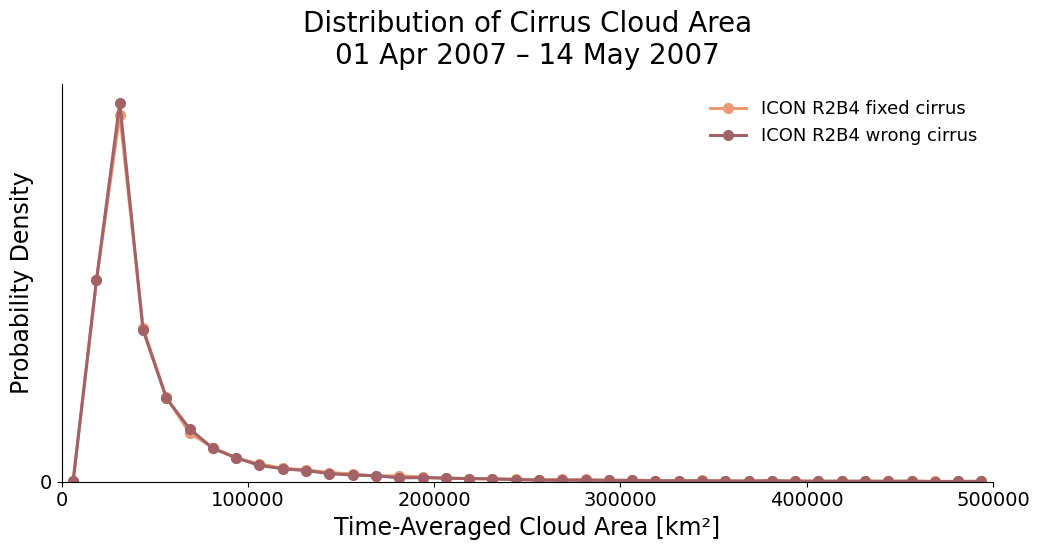

,Tracks plotted,Outside range,Missing/nonfinite,Mean (all finite),Median (all finite)
Experiment,,,,,
ICON R2B4 fixed cirrus,34635,173,0,56823.680139,33794.856771
ICON R2B4 wrong cirrus,24744,68,0,53007.618243,33153.967133


In [4]:
area_edges = np.linspace(0, 5e5, 41)
fig, ax, area_summary = plot_distribution(
    "avg_size[km]", area_edges,
    "Distribution of Cirrus Cloud Area", "Time-Averaged Cloud Area [km²]",
)
finish_figure(fig, "cirrus_cloud_area_distribution.png")
display(area_summary)

## 2. Cloud lifetime

Convert `track_length` to minutes. Match the reference's 20 histogram bins over 0–600 minutes. All selected cloud tracks contribute, regardless of phase evolution.

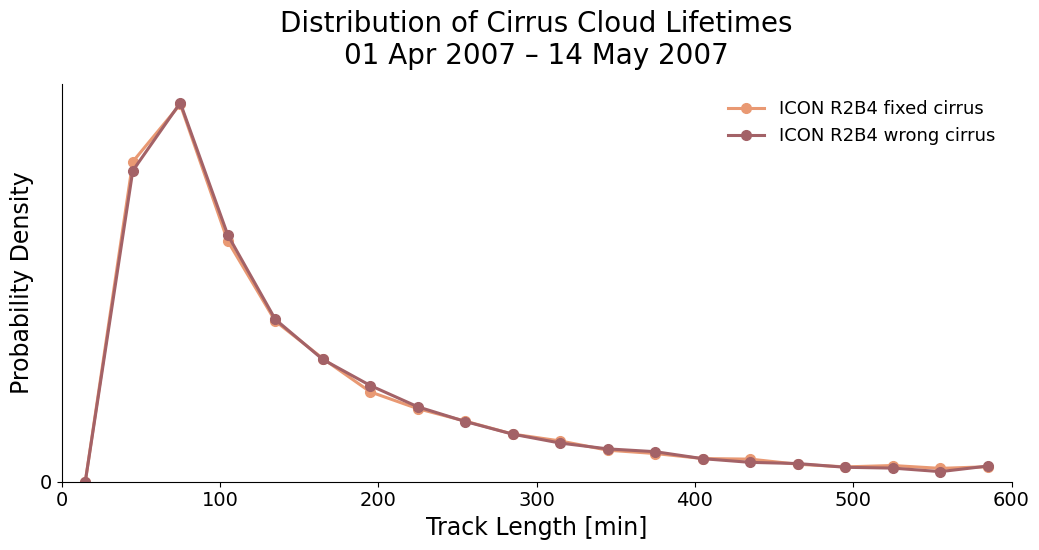

,Tracks plotted,Outside range,Missing/nonfinite,Mean (all finite),Median (all finite)
Experiment,,,,,
ICON R2B4 fixed cirrus,32511,2297,0,213.009222,105.0
ICON R2B4 wrong cirrus,23314,1498,0,205.338949,105.0


In [5]:
lifetime_edges = np.linspace(0, 600, 21)
fig, ax, lifetime_summary = plot_distribution(
    "lifetime_min", lifetime_edges,
    "Distribution of Cirrus Cloud Lifetimes", "Track Length [min]",
)
finish_figure(fig, "cirrus_cloud_lifetime_distribution.png")
display(lifetime_summary)

## 3. Average cloud-top temperature

Plot the per-track time-averaged cloud-top temperature (`avg_ctt`), with 2-degree display bins across the cirrus range. These display bins are finer than the six 10-degree bins used to identify tracks. Temperatures are converted using the agreed preprocessing offset (`avg_ctt − 273`).

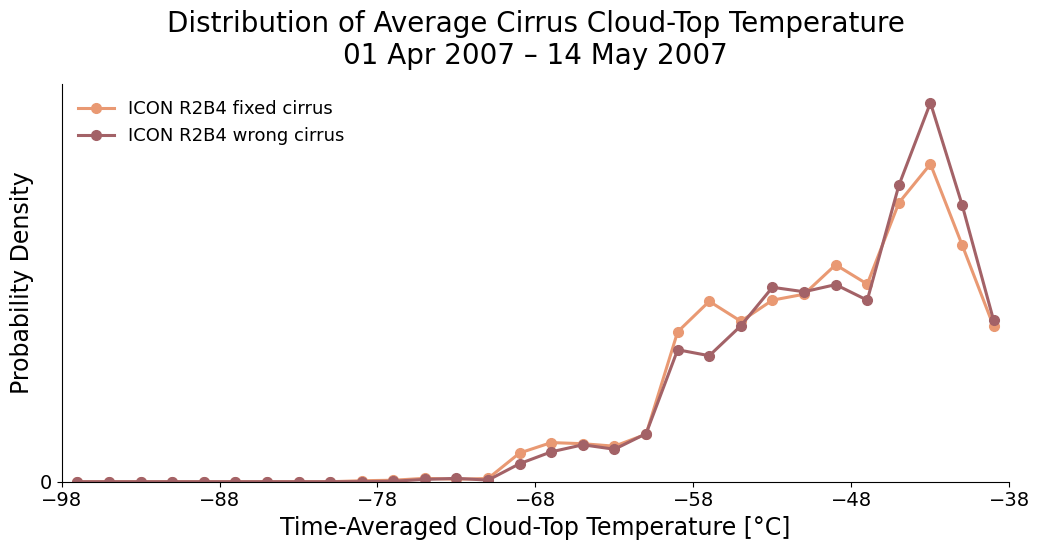

,Tracks plotted,Outside range,Missing/nonfinite,Mean (all finite),Median (all finite)
Experiment,,,,,
ICON R2B4 fixed cirrus,34808,0,0,-49.542759,-48.370269
ICON R2B4 wrong cirrus,24812,0,0,-48.769626,-47.275386


In [6]:
temperature_edges = np.arange(-98, -38 + 2, 2)
fig, ax, temperature_summary = plot_distribution(
    "avg_ctt_c", temperature_edges,
    "Distribution of Average Cirrus Cloud-Top Temperature", "Time-Averaged Cloud-Top Temperature [°C]",
)
ax.set_xticks(np.arange(-98, -38 + 10, 10))
finish_figure(fig, "cirrus_average_temperature_distribution.png")
display(temperature_summary)

## 4. Number of clouds

Count all selected cloud-track rows over the same comparison period, pooling hemispheres and temperature bins. These are raw track counts, not cloud occurrence rates. Tracks outside the area/lifetime display ranges remain included.

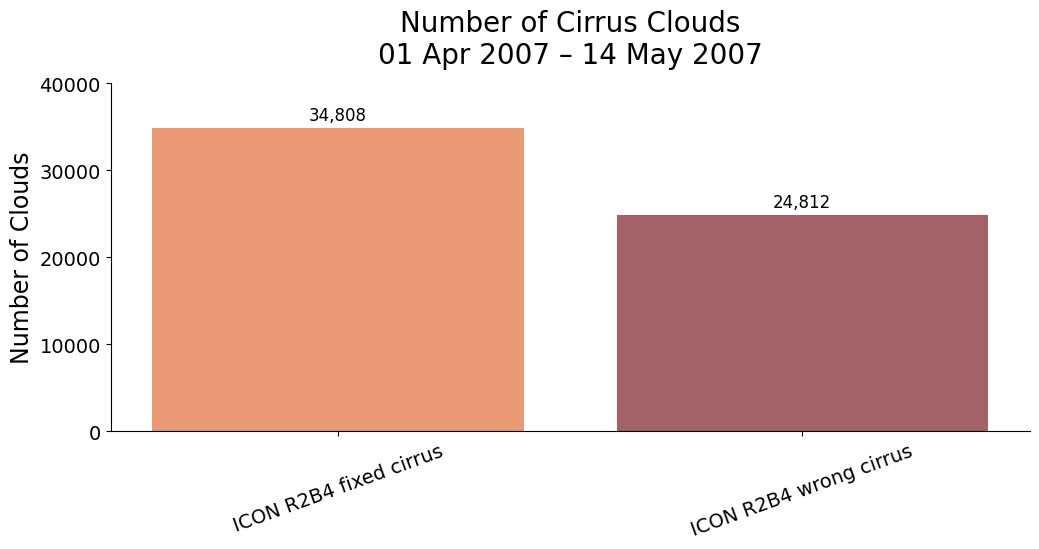

,Cloud tracks
ICON R2B4 fixed cirrus,34808
ICON R2B4 wrong cirrus,24812


In [7]:
cloud_counts = pd.Series({LABELS[run]: len(df) for run, df in clouds.items()}, name="Cloud tracks")
fig, ax = new_axes("Number of Cirrus Clouds", "", "Number of Clouds", density=False)
bars = ax.bar(cloud_counts.index, cloud_counts.values, color=[COLORS[run] for run in clouds])
ax.tick_params(axis="x", rotation=20)
ax.bar_label(bars, labels=[f"{count:,}" for count in cloud_counts], padding=3, fontsize=12)
ax.margins(y=0.15)
ax.set_ylim(bottom=0)
finish_figure(fig, "cirrus_number_of_clouds.png")
display(cloud_counts.to_frame())

## 5. Time-weighted cloud cover

Estimate the **time-mean tracked cloud area** over the comparison period:

$$\overline{A}_{\mathrm{tracked}} = \frac{\sum_i \overline{A}_i\,\Delta t_i}{T_{\mathrm{comparison}}}.$$

Use the same selected tracks and spatial filters as the plots. Clip each track's duration at the comparison end; its full-track average area is assumed representative of the clipped interval. Tracks starting before the selected period are excluded by the existing selection, so this is a selected-track estimate. Pool hemispheres and temperature bins as above; overlapping tracked areas are summed, not spatially deduplicated. No histogram range cuts apply.

The result is in **km²**, not a domain coverage percentage. Set `DOMAIN_AREA_KM2` to the actual observed domain area (matching the spatial selection) to also report percentage cover. Do not use the Earth's area unless it matches that domain. The comparison uses wrong cirrus as its reference.

In [14]:
# Optional: provide the area of the observed domain to obtain percentage cover.
DOMAIN_AREA_KM2 = None

period_hours = (end_time - start_time).total_seconds() / 3600
if period_hours <= 0:
    raise ValueError("Comparison period must have positive duration")
if DOMAIN_AREA_KM2 is not None and (
    not np.isfinite(DOMAIN_AREA_KM2) or DOMAIN_AREA_KM2 <= 0
):
    raise ValueError("DOMAIN_AREA_KM2 must be finite and positive")

cover_rows = {}
for run, df in clouds.items():
    area = df["avg_size[km]"].to_numpy(dtype=float)
    track_end = df.track_start_time + df.track_length
    clipped_start = df.track_start_time.clip(lower=start_time)
    clipped_end = track_end.clip(upper=end_time)
    hours = ((clipped_end - clipped_start).dt.total_seconds() / 3600).to_numpy(dtype=float)
    valid = np.isfinite(area) & (area >= 0) & np.isfinite(hours) & (hours > 0)
    area_time = float(np.sum(area[valid] * hours[valid]))
    mean_area = area_time / period_hours
    cover_rows[run] = {
        "Experiment": LABELS[run],
        "Valid tracks": int(valid.sum()),
        "Excluded tracks": int((~valid).sum()),
        "Comparison duration [h]": period_hours,
        "Integrated cloud area [km² h]": area_time,
        "Time-mean tracked area [km²]": mean_area,
    }
    if DOMAIN_AREA_KM2 is not None:
        cover_rows[run]["Time-weighted cloud cover [%]"] = 100 * mean_area / DOMAIN_AREA_KM2

cloud_cover = pd.DataFrame.from_dict(cover_rows, orient="index")
display(cloud_cover.set_index("Experiment"))
fixed_cover = cloud_cover.loc["fcirrus", "Time-mean tracked area [km²]"]
wrong_cover = cloud_cover.loc["wcirrus", "Time-mean tracked area [km²]"]
print(f"Period: {period_label}")
print("Time weighted cloud cover")
print(f"Fixed  cirrus: {fixed_cover:.2e} km²")
print(f"Wrong  cirrus: {wrong_cover:.2e} km²")
print(f"Fixed minus wrong cirrus: {fixed_cover - wrong_cover:.2e} km²")
if wrong_cover > 0:
    # print(f"Fixed / wrong cirrus scheme: {fixed_cover / wrong_cover:.4f}")
    print(f"Relative difference (fixed vs wrong): {100 * (fixed_cover / wrong_cover - 1):+.2f}%")
else:
    print("Ratio and relative difference are undefined because wrong-cirrus cover is zero")
if DOMAIN_AREA_KM2 is not None:
    print(f"Coverage difference: {100 * (fixed_cover - wrong_cover) / DOMAIN_AREA_KM2:+.4f} percentage points")

,Valid tracks,Excluded tracks,Comparison duration [h],Integrated cloud area [km² h],Time-mean tracked area [km²]
Experiment,,,,,
ICON R2B4 fixed cirrus,34808,0,1056.0,1.407589e+10,1.332944e+07
ICON R2B4 wrong cirrus,24812,0,1056.0,8.309627e+09,7.868965e+06


Period: 01 Apr 2007 – 14 May 2007
Time weighted cloud cover
Fixed  cirrus: 1.33e+07 km²
Wrong  cirrus: 7.87e+06 km²
Fixed minus wrong cirrus: 5.46e+06 km²
Relative difference (fixed vs wrong): +69.39%
